# Axis 1 — Adoption and profiles

**Owner: Member 1 · Branch: `axis-1` · Status: starting notebook, not a completed investigation.**

**Question:** How does reported AI use vary with experience and role?

**Use for the sponsor:** Identify profiles that may need different support during a pilot.

The proposed sponsor is a DINUM team planning an AI coding-assistant pilot. These French survey respondents are not a sample of DINUM staff. Use the shared population and denominator rules before changing them.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project root or its notebooks folder.")
sys.path.insert(0, str(ROOT))
from src.data import ensure_data, load_responses, load_schema
from src.population import prepare_population

ensure_data()
population = prepare_population(load_responses())
schema = load_schema()
print("2026 · France · coding as primary job · eligible respondents:", len(population))

2026 · France · coding as primary job · eligible respondents: 628


## 1. Check the fields and the answering population

In [2]:
fields = ['AISelect', 'WorkExp', 'Role', 'Employment']
display(schema.loc[schema["column"].isin(fields), ["column", "question", "sub", "transformation"]])
display(pd.DataFrame({"answered": population[fields].notna().sum(),
                      "unanswered": population[fields].isna().sum()}))

,column,question,sub,transformation
4,Employment,Which of the following best describes your cur...,NaN,Original answer
13,WorkExp,How many years have you been working professio...,NaN,Original answer
14,Role,Which of the following best describes your cur...,NaN,Original answer
99,AISelect,Do you currently use AI tools or AI agents in ...,NaN,"Distinct selections, semicolon-separated"


,answered,unanswered
AISelect,510,118
WorkExp,608,20
Role,627,1
Employment,628,0


## 2. A first descriptive view
This is a starting calculation. Record a factual observation and a separate question after inspecting it.

,group,answers,users,share_pct,sufficient_n
0,0–2 years,64,42,65.625,True
1,3–5 years,71,51,71.830986,True
2,6–10 years,107,84,78.504673,True
3,11–20 years,162,125,77.160494,True
4,21–80 years,84,69,82.142857,True


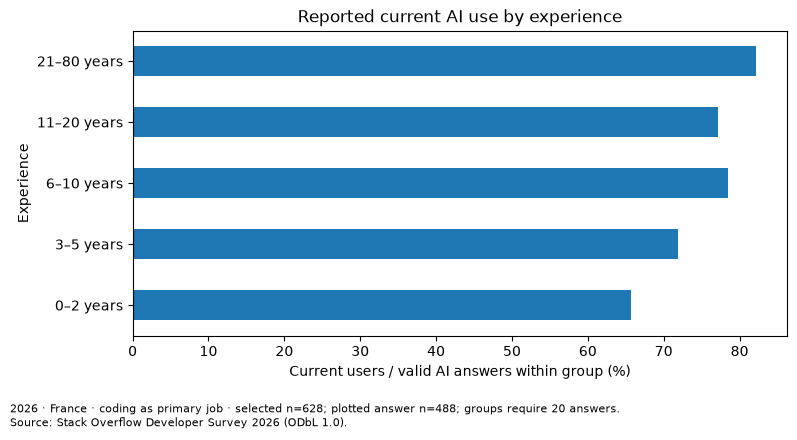

In [3]:
from src.analysis.axis_1 import summarise

table, available_n = summarise(population, "experience_group", minimum=20)
display(table)
shown = table.dropna(subset=["share_pct"])
used_n = int(shown["answers"].sum())
ax = shown.plot.barh(x="group", y="share_pct", legend=False, figsize=(8, 4))
ax.set(title="Reported current AI use by experience", xlabel="Current users / valid AI answers within group (%)", ylabel="Experience")
plt.figtext(.01, -.08, f"2026 · France · coding as primary job · selected n={len(population)}; plotted answer n={used_n}; groups require 20 answers.\nSource: Stack Overflow Developer Survey 2026 (ODbL 1.0).", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Work still to do — Member 1

1. Explore several useful views and write separate **I notice** / **I wonder** entries.
2. Formulate a testable hypothesis arising from those observations.
3. Compare one role or experience segment, show both user counts and answer counts, and check whether missing experience or a different minimum group size changes the interpretation.
4. Explain what the evidence supports, what remains uncertain and what cannot be concluded.
5. Add one useful interaction and one clear view to `views/axis_1.py`, with calculations in `src/analysis/axis_1.py`.
6. Check the shared app and explain the code. Ask the assigned reviewer to read the PR.

Write your own analysis below this plan. The starter calculation is not a finished individual submission.